# Imports

In [2]:
import os, gc, sys, traceback
os.environ["KERAS_BACKEND"] = "torch"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import keras
import torch
import datasets
import numpy as np
import transformers
import sklearn.metrics
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt

from pathlib import Path

In [3]:
keras.__version__, keras.backend.backend()

('3.16.0.dev2026110603', 'torch')

In [4]:
gpus = [torch.cuda.device(i) for i in range(torch.cuda.device_count())]
if gpus:
    try:
        torch.cuda.set_per_process_memory_fraction(0.9)
        for i in range(torch.cuda.device_count()):
           print(torch.cuda.get_device_properties(i))
    except:
        print("No GPU")

_CudaDeviceProperties(name='NVIDIA GeForce RTX 3060', major=8, minor=6, total_memory=12287MB, multi_processor_count=28, uuid=9c6396a2-0e5e-4445-8ae5-e68074710ca5, pci_bus_id=1, pci_device_id=0, pci_domain_id=0, L2_cache_size=2MB)


# Tokenizer

Train your own tokenizer on an English corpus or load a pretrained tokenizer for English sentences (see the one used in class)

In [5]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

# Dataset

Load the dataset (we will be using [imdb](https://huggingface.co/datasets/stanfordnlp/imdb)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset.

In [6]:
train_data = datasets.load_dataset('stanfordnlp/imdb', split='train')
test_data = datasets.load_dataset('stanfordnlp/imdb', split='test')

### Skip

In [5]:
class Tokenizer:
    def __init__(
        self,
        tokenizer_base: transformers.AutoTokenizer,
        texts: list[str],
    ):
        self.tokenizer_base = tokenizer_base

        used_tokens = set(token for tokens in tqdm.tqdm(tokenizer_base.encode(texts)) for token in tokens).union({tokenizer_base.bos_token_id, tokenizer_base.eos_token_id, tokenizer_base.pad_token_id})
        self.inner_tokens_dict = dict(zip(sorted(used_tokens), range(len(used_tokens))))
        self.inner_tokens_dict_inverse = {v: k for k, v in self.inner_tokens_dict.items()}
        
        self.tokens_dict = {tokenizer_base.decode(k): v for k, v in self.inner_tokens_dict.items()}

        self.eos_token_id = self.inner_tokens_dict[tokenizer_base.eos_token_id]
        self.bos_token_id = self.eos_token_id
        self.pad_token_id = self.eos_token_id


    def encode(self, enc_list: list):
        def enc(value):
            if isinstance(value, list):
                return [enc(v) for v in value]
            return [self.inner_tokens_dict[tokens_base] for tokens_base in self.tokenizer_base.encode(value)]

        return [enc(v) for v in tqdm.tqdm(enc_list)]

    def decode(self, enc_list: list):
        def dec(value: int):
            if isinstance(value, list):
                return [dec(v) for v in value]
            return self.inner_tokens_dict_inverse[value]

        return self.tokenizer_base.decode([dec(v) for v in tqdm.tqdm(enc_list)])

    def get_vocab(self):
        return self.tokens_dict
        

In [159]:
tokenizer = Tokenizer(tokenizer_base, train_data['text'][:] + test_data['text'][:])

  0%|          | 0/50000 [00:00<?, ?it/s]

In [67]:
len(tokenizer.get_vocab()), len(tokenizer_base.get_vocab())

(43949, 50257)

In [160]:
train_tokenized = tokenizer.encode(train_data['text'][:])

  0%|          | 0/25000 [00:00<?, ?it/s]

In [161]:
test_tokenized = tokenizer.encode(test_data['text'][:])

  0%|          | 0/25000 [00:00<?, ?it/s]

In [127]:
lengths_train = np.array(list(map(len, train_tokenized)))

In [128]:
lengths_test = np.array(list(map(len, test_tokenized)))

In [138]:
lengths_train[np.argpartition(lengths_train, -10)[-10:]], lengths_test[np.argpartition(lengths_test, -10)[-10:]]

(array([1764, 1788, 1862, 2002, 2072, 2116, 2140, 2174, 2350, 3097]),
 array([1487, 1519, 1523, 1539, 1608, 1787, 2228, 2817, 2875, 2972]))

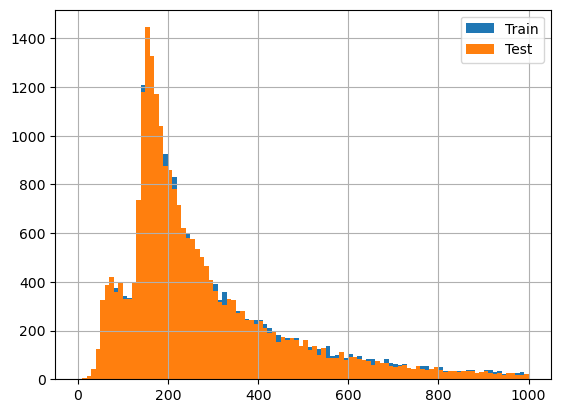

In [139]:
plt.grid()
plt.hist(lengths_train, bins=100, range=(0, 1000)), plt.hist(lengths_test, bins=100, range=(0, 1000))
# plt.loglog()
plt.legend(["Train", "Test"])

### Continue

In [7]:
class Dataset(keras.utils.PyDataset):

    def __init__(
            self,
            data: datasets.Dataset,
            *,
            tokenizer,
            max_len: int,
            batch_size: int,
            seed: int | None = None, 
            shuffle: bool = False, 
            **kwargs
    ):
        super().__init__(**kwargs)
        self.shuffle = shuffle
        self.batch_size = batch_size
        self.seed = seed
        self.rng = np.random.default_rng(seed)
        
        self.X = tokenizer(data['text'][:])['input_ids']
        self.y = np.asarray(data['label'])

        self.tokenizer = tokenizer
        self.max_len = max_len

        self.indexes = np.arange(len(self.X))

        self.on_epoch_end()

    def __len__(self):
        return (len(self.indexes) + self.batch_size - 1) // self.batch_size
        # return len(self.indexes) // self.batch_size

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indexes)
    
    def __getitem__(self, index: int):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        batch = self.indexes[start:end]

        _X = [self.X[i] for i in batch]
        _X = keras.utils.pad_sequences(_X, maxlen=self.max_len, padding='post', truncating='post', value=tokenizer.pad_token_id)

        return _X, self.y[batch]


In [8]:
MAX_LENGTH = 256
BATCH_SIZE = 64

In [9]:
train_dataset = Dataset(train_data, tokenizer=tokenizer, max_len=MAX_LENGTH, batch_size=BATCH_SIZE, shuffle=True)

Token indices sequence length is longer than the specified maximum sequence length for this model (1168 > 1024). Running this sequence through the model will result in indexing errors


In [10]:
test_dataset = Dataset(test_data, tokenizer=tokenizer, max_len=MAX_LENGTH, batch_size=BATCH_SIZE, shuffle=False)

In [11]:
from collections import Counter

Counter(i.shape for i, _ in train_dataset), Counter(i.shape for i, _ in test_dataset)

(Counter({(64, 256): 390, (40, 256): 1}),
 Counter({(64, 256): 390, (40, 256): 1}))

# Model

Implement your model. The model should have the Transformer architecture. Remember to mask out padding tokens.

In [12]:
@keras.saving.register_keras_serializable()
class PaddingMask(keras.layers.Layer):
    def __init__(
        self, 
        pad_token_id: int, 
        add_cls: bool,
        num_registers: int = 0,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.pad_token_id = pad_token_id
        self.num_registers = num_registers
        self.add_cls = add_cls

    def compute_output_shape(self, input_shape):
        b, l = input_shape
        if l is not None:
            l += int(self.add_cls) + self.num_registers
        return (b, 1, l)

    def call(self, x):
        if self.add_cls:
            x = keras.ops.pad(x, pad_width=((0, 0), (1, 0)), constant_values=-1)
        if self.num_registers > 0:
            x = keras.ops.pad(x, pad_width=((0, 0), (0, self.num_registers)), constant_values=-1)
        mask = x != self.pad_token_id
        return keras.ops.expand_dims(mask, 1)

    def get_config(self):
        config = super().get_config()
        config.update({
            "pad_token_id": self.pad_token_id,
            "add_cls": self.add_cls,
            "num_registers": self.num_registers,
        })
        return config

In [13]:
@keras.saving.register_keras_serializable()
class Embedding(keras.layers.Layer):

    def __init__(
        self,
        vocab_size: int,
        embedding_size: int,
        max_length: int,
        num_registers: int = 0,
        add_cls: bool = True,
        **kwargs
    ):
        super().__init__(**kwargs)
        
        self.embedding_size = embedding_size
        self.max_length = max_length
        self.add_cls = add_cls
        self.num_registers = num_registers
        
        self.embedding = keras.layers.Embedding(vocab_size, embedding_size)

    def build(self, input_shape):
        self.pos_embed = self.add_weight((1, self.max_length, self.embedding_size), name='pos_embed')
        if self.add_cls:
            self.cls = self.add_weight((1, 1, self.embedding_size), name='cls')
        if self.num_registers > 0:
            self.registers = self.add_weight((1, self.num_registers, self.embedding_size), name='registers')

        super().build(input_shape)

    def call(self, x: keras.KerasTensor) -> keras.KerasTensor:
        b, l = keras.ops.shape(x)
        x = self.embedding(x)
        x = x + self.pos_embed[:, :l, :]
        if self.add_cls:
            cls = keras.ops.broadcast_to(self.cls, (b, 1, self.embedding_size))
            x = keras.ops.concatenate([cls, x], axis=1)
        if self.num_registers > 0:
            registers = keras.ops.broadcast_to(self.registers, (b, self.num_registers, self.embedding_size))
            x = keras.ops.concatenate([x, registers], axis=1)

        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            "vocab_size": self.embedding.input_dim,
            "embedding_size": self.embedding_size,
            "max_length": self.max_length,
            "num_registers": self.num_registers,
            "add_cls": self.add_cls,
        })
        return config

In [15]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [60]:
def get_model(
    vocab_size: int,
    embedding_size: int,
    max_length: int,
    num_blocks: int,
    num_heads: int,
    pad_token_id: int,
    num_registers: int = 0,
    name: str | None = None,
    return_attention_scores: bool = False,
) -> keras.Model:
    '''Creates a model with Transformer architecture for binary sequence classification.

    Arguments:
        vocab_size: size of the tokenizer vocabulary
        embedding_size: size of the internal mdoel representations 
        max_length: maximal allowed sequence length
        num_blocks: number of transformer blocks
        num_heads: number of multi head attentions heads
        pad_token_id: id of the padding token
        num_registers: number of additional items in sequences
        name: the model name

    Returns:
        The model'''

    assert embedding_size % 4 == 0

    inputs = x = keras.layers.Input((None, ), dtype='int32', name="input")
    mask = PaddingMask(pad_token_id=pad_token_id, add_cls=True, num_registers=num_registers, name="padding_mask")(x)
    x = Embedding(vocab_size, embedding_size, max_length, add_cls=True, num_registers=num_registers, name='embedding')(x)
    x = keras.layers.LayerNormalization(name='ln')(x)

    ff_features = embedding_size * 4
    attention_scores = []

    for i in range(num_blocks):
        block_name = f'block_{i}'

        mha = keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embedding_size // num_heads, name=get_name(block_name, 'mha'))

        if return_attention_scores:
            y, attn = mha(x, x, attention_mask=mask, return_attention_scores=True)
            attention_scores.append(attn)
        else:
            y = mha(x, x, attention_mask=mask)
        
        x = keras.layers.Add(name=get_name(block_name, 'add1'))([x, y])
        x = keras.layers.LayerNormalization(name=get_name(block_name, 'ln1'))(x)

        y_value = keras.layers.Dense(ff_features, name=get_name(block_name, 'swiglu_value'))(x)
        y_gate  = keras.layers.Dense(ff_features, name=get_name(block_name, 'swiglu_gate'), activation='swish')(x)
        y = keras.layers.Multiply(name=get_name(block_name, 'swiglu'))([y_gate, y_value])
        y = keras.layers.Dense(embedding_size, name=get_name(block_name, 'ff'))(y)
        
        x = keras.layers.Add(name=get_name(block_name, 'add2'))([x, y])
        x = keras.layers.LayerNormalization(name=get_name(block_name, 'ln2'))(x)

    x = x[:, 0]
    x = keras.layers.Dense(1, name='output')(x)

    if return_attention_scores:
        outputs = {
            "logits": x,
            "attention_scores": keras.ops.stack(attention_scores),
        }
    else:
        outputs = x

    return keras.models.Model(inputs=inputs, outputs=outputs, name=name)

# Training

Train the model. Choose model size, batch size, loss, learning rate schedule.

In [51]:
model = get_model(
    vocab_size=len(tokenizer.get_vocab()),
    embedding_size=128,
    max_length=MAX_LENGTH,
    num_blocks=6,
    num_heads=8,
    pad_token_id=tokenizer.pad_token_id,
    num_registers=4,
    name='transformer_cls',
    return_attention_scores=False,
)

In [52]:
model.summary()

Model: "transformer_cls"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 128) │  6,466,304 │ input[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ln                  │ (None, None, 128) │        256 │ embedding[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ padding_mask        │ (None, 1, None)   │          0 │ input[0][0]       │
│ (PaddingMask)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_mha         │ (None, None, 128) │     66,048 │ ln[0][0],         │
│ (MultiHeadAttentio… │                   │            │ ln[0][0],         │
│                     │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_add1 (Add)  │ (None, None, 128) │          0 │ ln[0][0],         │
│                     │                   │            │ block_0_mha[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_ln1         │ (None, None, 128) │        256 │ block_0_add1[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_swiglu_gate │ (None, None, 512) │     66,048 │ block_0_ln1[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_swiglu_val… │ (None, None, 512) │     66,048 │ block_0_ln1[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_swiglu      │ (None, None, 512) │          0 │ block_0_swiglu_g… │
│ (Multiply)          │                   │            │ block_0_swiglu_v… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_ff (Dense)  │ (None, None, 128) │     65,664 │ block_0_swiglu[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_add2 (Add)  │ (None, None, 128) │          0 │ block_0_ln1[0][0… │
│                     │                   │            │ block_0_ff[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_0_ln2         │ (None, None, 128) │        256 │ block_0_add2[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_mha         │ (None, None, 128) │     66,048 │ block_0_ln2[0][0… │
│ (MultiHeadAttentio… │                   │            │ block_0_ln2[0][0… │
│                     │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_add1 (Add)  │ (None, None, 128) │          0 │ block_0_ln2[0][0… │
│                     │                   │            │ block_1_mha[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_ln1         │ (None, None, 128) │        256 │ block_1_add1[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_swiglu_gate │ (None, None, 512) │     66,048 │ block_1_ln1[0][0

 Total params: 8,052,609 (30.72 MB)

 Trainable params: 8,052,609 (30.72 MB)

 Non-trainable params: 0 (0.00 B)

In [53]:
EPOCHES = 5

In [54]:
model.compile(
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    optimizer=keras.optimizers.AdamW(
        keras.optimizers.schedules.CosineDecay(
            initial_learning_rate=5e-4,
            decay_steps=EPOCHES * len(train_dataset),
            alpha=1e-4,
        )
    ),
    metrics=[
        'accuracy',
    ]
)

In [55]:
with torch.no_grad():
    torch.cuda.empty_cache()
torch.cuda.empty_cache()
if sys.last_traceback:
    traceback.clear_frames(sys.last_traceback)
gc.collect(), torch.cuda.memory_allocated(), torch.cuda.memory_reserved()

(43050, 210309120, 270532608)

In [56]:
SAVE_MODEL_PATH = Path("./saved")
SAVE_MODEL_PATH.mkdir(parents=True, exist_ok=True)

In [57]:
model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHES,
    callbacks=[
            keras.callbacks.ModelCheckpoint(
            SAVE_MODEL_PATH / f"{model.name}.keras",
            save_best_only=True,
        ),
        keras.callbacks.CSVLogger(
            SAVE_MODEL_PATH / f"log_{model.name}.csv", 
            separator=",",
            append=True,
        ),
    ]
)

Epoch 1/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 78s 198ms/step - accuracy: 0.6572 - loss: 0.5564 - val_accuracy: 0.8478 - val_loss: 0.3276
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 77s 197ms/step - accuracy: 0.9194 - loss: 0.2043 - val_accuracy: 0.8556 - val_loss: 0.3659
Epoch 3/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 77s 197ms/step - accuracy: 0.9769 - loss: 0.0753 - val_accuracy: 0.8399 - val_loss: 0.5091
Epoch 4/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 77s 196ms/step - accuracy: 0.9937 - loss: 0.0288 - val_accuracy: 0.8385 - val_loss: 0.6801
Epoch 5/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 79s 202ms/step - accuracy: 0.9971 - loss: 0.0176 - val_accuracy: 0.8388 - val_loss: 0.7398


# Evaluation

Evaluate the model you trained on the test dataset. Plot the ROC curve.

In [23]:
def plot_roc_curve(
    X: np.ndarray,
    y: np.ndarray,
    model: keras.Model,
    ax: plt.Axes | None = None,
    is_legend: bool = False,
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''

    if ax is None:
        ax = plt.gca()

    y_pred = keras.ops.sigmoid( model.predict(X) ).cpu()

    disp = sklearn.metrics.RocCurveDisplay.from_predictions(
        y, 
        y_pred, 
        name=f"Class {i}",
        ax=ax
    )

    ax.plot([0, 1], [0, 1], "k--")
    ax.grid(True)
    mean_auc = sklearn.metrics.roc_auc_score(y, y_pred)

    if not is_legend:
        ax.get_legend().remove()

    ax.set_title(f"ROC AUC: {mean_auc:.3f}")

    return mean_auc

391/391 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step


0.9088143072000001

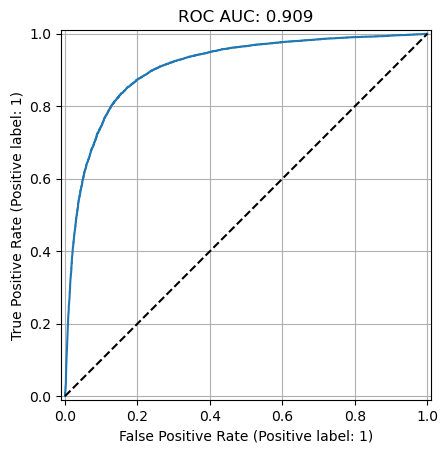

In [24]:
plot_roc_curve(test_dataset, test_dataset.y, model)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [25]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None) -> int:
    '''Computes the model output for `text` and outputs the predicted label

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        Predicted label'''
    tokens = np.array(tokenizer.encode([text], max_length=max_length))

    pred = model.predict(tokens, verbose=0).flat[0]

    return (pred > threshold).astype(int)

In [26]:
I = -11
print(test_data['text'][I])
(label_text(test_data['text'][I], model, max_length=MAX_LENGTH), test_data['label'][I])

Adam (Eric Jungmann) and obnoxious best friend Harley (Justin Urich) are driving cross country to a wedding. Along the way they pick up sexy hitchhiker Sarah (Aimee Brooks). Then, for no reason, a monster truck keeps trying to run them off the road...and maybe kill them. Who is doing this and why?<br /><br />Pretty good horror film. Its energetic and full of flashy direction which gets you right into the action. It's also a horror comedy. Most of the humor is infantile and REALLY gross but actually somewhat funny. Also this movie really piles on the gore at times--but that's a GOOD thing! The acting is OK--Jungmann overplays his nerd role a bit much; Urich is stuck with the hopeless role of the foul-mouthed, sex-obsessed best friend--but pulls it off; Brooks is good too in a limited role.<br /><br />BUT I could see the "twist" ending coming long before it happened and logic totally disappears at the end (especially the rescue). Still, this is a gory, sometimes funny and sometimes scary

(np.int64(0), 1)

In [27]:
texts = [
    "I hate this movie... It is not interesting. I should have never seen this one.",
    "I hate this movie! It is not interesting.",
    
    "We really loved this movie! It is very fun.",

    "Hated.",
    "Disgusting.",
    "Fun!",

    "0/10",
    "10/10",
    "11/10",

    # 10
    "I'm still so emotional after everything what happened. When I've started watching this show I was afraid the plot won't be interesting, but I was mistaken. The more I watched, the more I enjoyed it. At the beginning I used to like Pavi more than Nisha, but now I like them both equally and can't wait for further seasons. This show has a lot of potential. Please, don't waste it.",
    # 6
    "Vision has treacherous Ultron living upstairs in his house. Rather than just deleting Ultron. Vision ignores that his security is breached.<br /><br />When Disney+ started. They spent millions on shows like Wandavision and the high concept of the sitcom of the week.<br /><br />This one took a long time to make its point and reveal its main plot. It is also lower budget with only one mundane action sequence.",
    # 8
    "Seven Havens S1 took a few episodes to find its feet, but the latter half of the season has built steadily towards this conclusion. It delivers on the promise of the series and leaves me genuinely eager for the next season.",
    # 2
    "In his first appearance, he lifted Thor's hammer. After that, he loses every battle. No power, no skill, no tactics.<br /><br />People didn't love Tony Stark because he had a six-pack or because he was good at hand-to-hand combat. They loved him because whenever he got into a fight, you knew he would do whatever it took to win.<br /><br />That's what made Tony Stark great. He was smart, resourceful, and unpredictable. He adapted to the situation instead of standing around talking.<br /><br />Vision, on the other hand, has incredible powers but rarely seems to do anything meaningful with them. All that power, and barely any action.<br /><br />Stop wasting great characters by making them look useless."
]

for t in texts:
    print(t.replace("<br /><br />", "\n"), label_text(t, model, max_length=MAX_LENGTH), '', sep='\n')

I hate this movie... It is not interesting. I should have never seen this one.
0

I hate this movie! It is not interesting.
0

We really loved this movie! It is very fun.
1

Hated.
1

Disgusting.
0

Fun!
1

0/10
1

10/10
1

11/10
1

I'm still so emotional after everything what happened. When I've started watching this show I was afraid the plot won't be interesting, but I was mistaken. The more I watched, the more I enjoyed it. At the beginning I used to like Pavi more than Nisha, but now I like them both equally and can't wait for further seasons. This show has a lot of potential. Please, don't waste it.
0

Vision has treacherous Ultron living upstairs in his house. Rather than just deleting Ultron. Vision ignores that his security is breached.
When Disney+ started. They spent millions on shows like Wandavision and the high concept of the sitcom of the week.
This one took a long time to make its point and reveal its main plot. It is also lower budget with only one mundane action seque

# Bonus

Inspect the model attention scores with respect to words and punctuation in the sentence. What does the model consider when classifying the sentence.

In [61]:
probe = get_model(
    vocab_size=len(tokenizer.get_vocab()),
    embedding_size=128,
    max_length=MAX_LENGTH,
    num_blocks=6,
    num_heads=8,
    pad_token_id=tokenizer.pad_token_id,
    num_registers=4,
    name='transformer_cls',
    return_attention_scores=True,
)
probe.set_weights(model.get_weights())

In [155]:
token_ids = tokenizer(texts[2], return_tensors='np')["input_ids"][0]
tokens = [t.replace("Ġ", "_") for t in tokenizer.convert_ids_to_tokens(token_ids)]
texts[2], token_ids, tokens

('We really loved this movie! It is very fun.',
 array([1135, 1107, 6151,  428, 3807,    0,  632,  318,  845, 1257,   13]),
 ['We',
  '_really',
  '_loved',
  '_this',
  '_movie',
  '!',
  '_It',
  '_is',
  '_very',
  '_fun',
  '.'])

In [159]:
res = probe(token_ids[None])
attention_scores = res['attention_scores'].detach().cpu().numpy()
logit = res['logits']

https://agombert.github.io/AdvancedNLPClasses/chapter5/Session_5_2_Attention_Visualization/#interactive-tool

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from ipywidgets import interact, IntSlider

def heatmap(attention_scores, tokens, name, ax=None):
    sns.heatmap(
        attention_scores, 
        xticklabels=tokens, 
        yticklabels=tokens, 
        cmap="viridis", 
        ax=ax, 
        cbar=True,
        square=True,
    )
    ax.set_title(name)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    

def plot_all_heads_in_layer(tokens, attention_matrix, layer=0, num_heads=None):
    if num_heads is None:
        num_heads = attention_matrix.shape[2]  # Get number of heads

    num_subplots = num_heads + 1
    
    fig, axes = plt.subplots(
        nrows=int(np.ceil(num_subplots / 4)), 
        ncols=min(4, num_subplots),
        figsize=(20, 5 * int(np.ceil(num_subplots / 4)))
    )
    axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]
    
    for head_idx in range(num_heads):
        heatmap(
            attention_matrix[layer, 0, head_idx],
            tokens,
            f"Head {head_idx}",
            axes[head_idx],
        )

    heatmap(
        attention_matrix[layer, 0].mean(axis=0),
        tokens,
        f"Mean",
        axes[num_heads],
    )

    for j in range(num_heads + 1, len(axes)):
        axes[j].axis("off")
    
    # cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    # fig.colorbar(axes[0].collections[0], cax=cbar_ax)
    
    plt.suptitle(f"All Attention Heads in Layer {layer}", fontsize=16)
    plt.tight_layout()
    return fig

def interactive_layer_attention(tokens, attention_matrix):
    num_layers = attention_matrix.shape[0]

    ##
    num_tokens = attention_matrix.shape[-1]
    num_registers = num_tokens - len(tokens) - 1
    tokens = ['[CLS]'] + tokens + [f'[REG{i}]' for i in range(num_registers)]
    ##
    
    print(f"Created dictionary with {attention_matrix.shape[0]} layers")
    
    @interact(layer=IntSlider(min=0, max=num_layers-1, step=1, value=0))
    def update(layer):
        plot_all_heads_in_layer(tokens, attention_matrix, layer)
        

In [ ]:
def make_good(text: str, model, tokenizer):
    print(repr(text))
    token_ids = tokenizer(text, return_tensors='np')["input_ids"][0]
    tokens = [t.replace("Ġ", "_") for t in tokenizer.convert_ids_to_tokens(token_ids)]
    
    res = probe(token_ids[None])
    attention_scores = res['attention_scores'].detach().cpu().numpy()
    logit = res['logits']

    interactive_layer_attention(tokens, attention_scores)

In [ ]:
make_good(texts[0], model, tokenizer)